# Homework assignment #3

## 1. Apply a Logistic Regression model

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(42)
df = pd.read_csv('bioresponse.csv')

X = df.iloc[:, 1:].to_numpy(dtype=float)
Y = df.iloc[:, 0].to_numpy(dtype=int)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=42)

train_set_x = X_train.T
train_set_y = Y_train.reshape(1, -1)
test_set_x = X_test.T
test_set_y = Y_test.reshape(1, -1)

print('Shape:', df.shape)
print('Train:', train_set_x.shape, 'Test:', test_set_x.shape)

Shape: (3751, 1777)
Train: (1776, 2813) Test: (1776, 938)


In [42]:
def sigmoid(z):
    return 1./(1.+np.exp(-z))

def initialize_with_zeros(dim):
    w = np.zeros((dim, 1))
    b = 0.
    return w, b

def propagate(w, b, X, Y):
    m = X.shape[1]
    A = sigmoid(np.dot(w.T,X)+b )
    A = np.clip(A, 1e-12, 1 - 1e-12)
    cost = -(1./m)*np.sum(Y*np.log(A)+(1-Y)*np.log(1-A),axis=1)
    dw = (1./m)*np.dot(X,(A-Y).T)
    db = (1./m)*np.sum(A-Y,axis=1)
    return {"dw": dw, "db": db}, cost

def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    costs = []
    for i in range(num_iterations):
        grads, cost = propagate(w,b,X,Y)
        dw = grads["dw"]
        db = grads["db"]

        w -=learning_rate * dw
        b -=learning_rate * db

        if i % 100 == 0:
            costs.append(cost)

        if print_cost and i % 100 == 0:
            print (f"Cost after iteration {i}: {round(cost[0], 7)}")

    params = {"w": w, "b": b}
    grads = {"dw": dw, "db": db}

    return params, grads, costs

def predict(w, b, X, threshold):
    m = X.shape[1]
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1)
    A = sigmoid(np.dot(w.T,X)+b)
    for i in range(A.shape[1]):
        if (A[0,i]<=threshold):
            Y_prediction[0][i]=0
        else:
            Y_prediction[0][i]=1

    return Y_prediction

def model(X_train, Y_train, X_test, Y_test, num_iterations = 2000, learning_rate = 0.5, print_cost = False):
    w, b = initialize_with_zeros(X_train.shape[0])
    parameters, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)

    w = parameters["w"]
    b = parameters["b"]

    Y_prediction_test = predict(w, b, X_test, 0.5)
    Y_prediction_train = predict(w, b, X_train, 0.5)

    print(f"train accuracy: {100 - np.mean(np.abs(Y_prediction_train - Y_train) * 100)}")
    print(f"test accuracy: {100 - np.mean(np.abs(Y_prediction_test - Y_test) * 100)}")

    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train" : Y_prediction_train,
         "w" : w,
         "b" : b,
         "learning_rate" : learning_rate,
         "num_iterations": num_iterations}

    return d


d_gd = model(train_set_x, train_set_y, test_set_x, test_set_y, num_iterations=300, learning_rate=0.01, print_cost=False)
print('GD test accuracy:', 100 - np.mean(np.abs(d_gd['Y_prediction_test'] - test_set_y) * 100))

train accuracy: 73.19587628865979
test accuracy: 73.02771855010661
GD test accuracy: 73.02771855010661


## 2. Modify optimize() function to implement the stochastic gradient descent (SGD) method

In [43]:
def optimize_sgd(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    costs = []
    m = X.shape[1]
    rng = np.random.default_rng(42)
    for i in range(num_iterations):
        for j in rng.permutation(m):
            grads, cost = propagate(w, b, X[:, j:j+1], Y[:, j:j+1])
            dw = grads['dw']
            db = grads['db']
            w -= learning_rate * dw
            b -= learning_rate * db
        grads, cost = propagate(w, b, X, Y)
        costs.append(float(cost[0]))
        if print_cost and i % 10 == 0:
            print(f'Cost after epoch {i}: {cost[0]:.7f}')
    params = {'w': w, 'b': b}
    return params, grads, costs

## 3. Implement the Adam optimization method

In [44]:
def optimize_adam(w, b, X, Y, num_iterations, learning_rate, print_cost = False):
    costs = []
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    mw, vw = np.zeros_like(w), np.zeros_like(w)
    mb, vb = np.zeros_like(b), np.zeros_like(b)
    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads['dw'], grads['db']
        mw = beta1 * mw + (1 - beta1) * dw
        vw = beta2 * vw + (1 - beta2) * dw**2
        mb = beta1 * mb + (1 - beta1) * db
        vb = beta2 * vb + (1 - beta2) * db**2
        t = i + 1
        w -= learning_rate * (mw / (1 - beta1**t)) / (np.sqrt(vw / (1 - beta2**t)) + eps)
        b -= learning_rate * (mb / (1 - beta1**t)) / (np.sqrt(vb / (1 - beta2**t)) + eps)
        if i % 100 == 0:
            costs.append(float(cost[0]))
        if print_cost and i % 100 == 0:
            print(f'Cost after iteration {i}: {cost[0]:.7f}')
    return {'w': w, 'b': b}, grads, costs

## 4. Plot learning curves

      Train accuracy, %  Test accuracy, %
GD                73.20             73.03
SGD               75.40             73.45
Adam              82.79             76.01


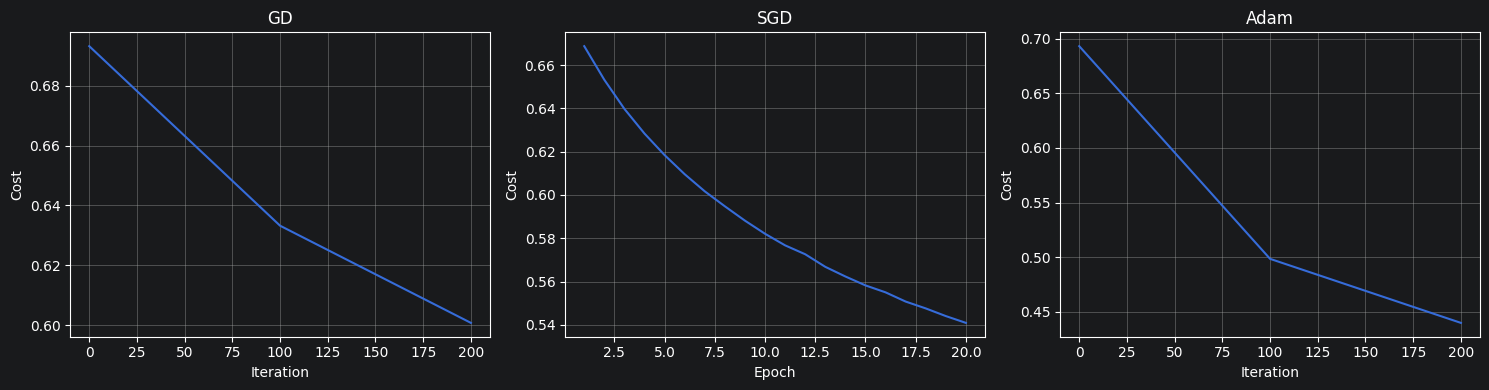

In [45]:
def run_optimizer(method, iterations, learning_rate):
    w, b = initialize_with_zeros(train_set_x.shape[0])
    if method == 'GD':
        params, grads, costs = optimize(w, b, train_set_x, train_set_y, iterations, learning_rate)
        x_axis = np.arange(len(costs)) * 100
    elif method == 'SGD':
        params, grads, costs = optimize_sgd(w, b, train_set_x, train_set_y, iterations, learning_rate)
        x_axis = np.arange(1, len(costs) + 1)
    else:
        params, grads, costs = optimize_adam(w, b, train_set_x, train_set_y, iterations, learning_rate)
        x_axis = np.arange(len(costs)) * 100
    pred_train = predict(params['w'], params['b'], train_set_x, 0.5)
    pred_test = predict(params['w'], params['b'], test_set_x, 0.5)
    return {'costs': costs, 'x_axis': x_axis,
            'train_accuracy': 100 - np.mean(np.abs(pred_train - train_set_y) * 100),
            'test_accuracy': 100 - np.mean(np.abs(pred_test - test_set_y) * 100)}

experiments = {
    'GD': run_optimizer('GD', 300, 0.01),
    'SGD': run_optimizer('SGD', 20, 0.0001),
    'Adam': run_optimizer('Adam', 300, 0.001),
}
comparison = pd.DataFrame({name: {'Train accuracy, %': r['train_accuracy'],
                                   'Test accuracy, %': r['test_accuracy']}
                           for name, r in experiments.items()}).T
print(comparison.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, r) in zip(axes, experiments.items()):
    ax.plot(r['x_axis'], r['costs'])
    ax.set_title(name)
    ax.set_xlabel('Epoch' if name == 'SGD' else 'Iteration')
    ax.set_ylabel('Cost')
    ax.grid()
plt.tight_layout()
plt.show()

## 5. Train the models with different values of the learning rate

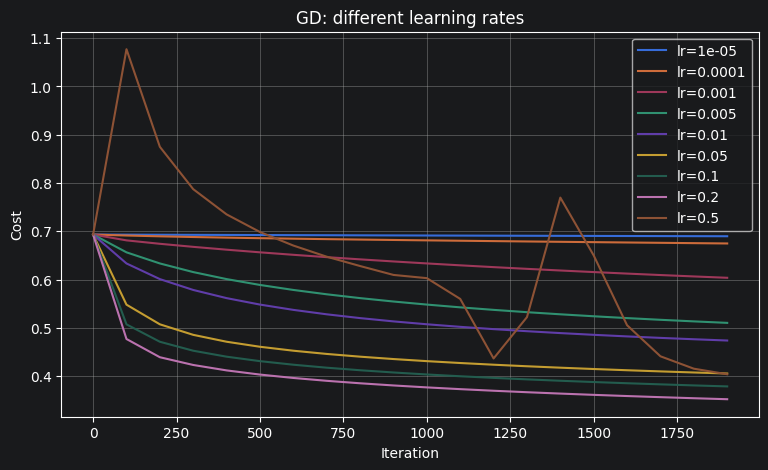

Learning rate  Train accuracy, %  Test accuracy, %
        1e-05              53.29             57.04
       0.0001              57.63             60.66
        0.001              72.52             72.71
        0.005              77.11             74.73
         0.01              78.35             75.59
         0.05              82.26             76.97
          0.1              83.33             76.44
          0.2              84.93             75.37
          0.5              83.83             72.92

GD:
Best learning rate: 0.05
Best test accuracy: 76.97%



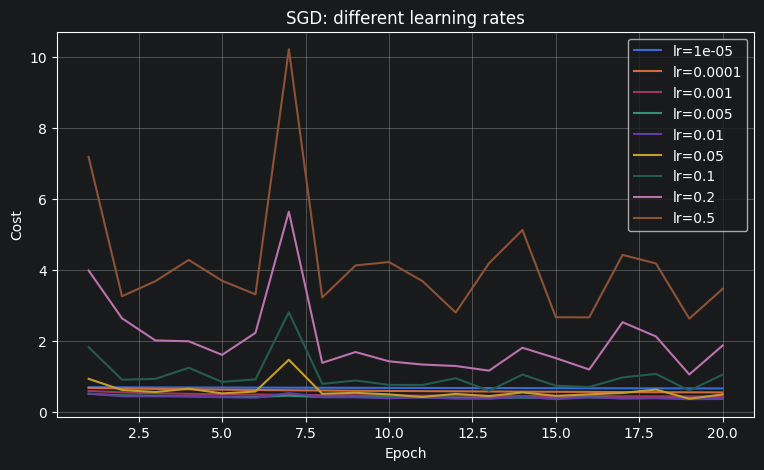

Learning rate  Train accuracy, %  Test accuracy, %
        1e-05              65.30             68.87
       0.0001              75.40             73.45
        0.001              80.95             76.76
        0.005              83.47             75.80
         0.01              83.68             76.65
         0.05              82.87             74.31
          0.1              79.10             73.03
          0.2              78.85             72.81
          0.5              79.84             72.60

SGD:
Best learning rate: 0.001
Best test accuracy: 76.76%



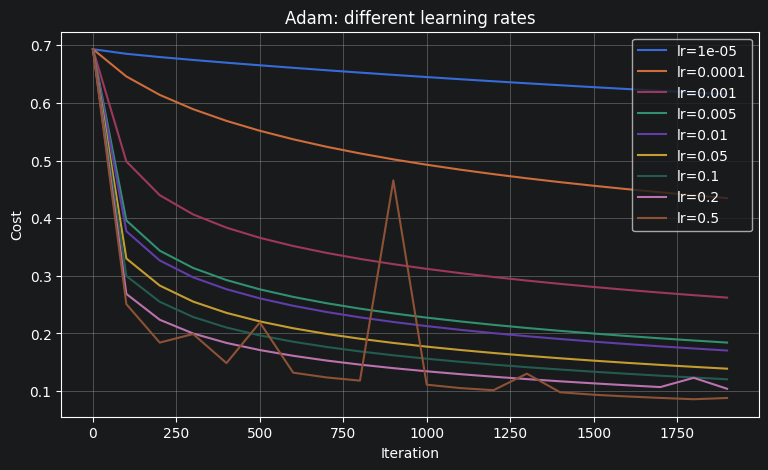

Learning rate  Train accuracy, %  Test accuracy, %
        1e-05              71.03             70.90
       0.0001              81.91             76.12
        0.001              89.94             75.59
        0.005              94.03             73.56
         0.01              94.53             72.49
         0.05              95.34             71.00
          0.1              95.77             70.90
          0.2              96.45             69.83
          0.5              97.30             69.51

Adam:
Best learning rate: 0.0001
Best test accuracy: 76.12%



In [46]:
learning_rates = [0.00001, 0.0001, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5]

iterations = {
    'GD': 2000,
    'SGD': 20,
    'Adam': 2000
}

lr_results = {}

for method in ['GD', 'SGD', 'Adam']:

    lr_results[method] = {}
    plt.figure(figsize=(9, 5))

    for lr in learning_rates:
        r = run_optimizer(method, iterations[method], lr)
        lr_results[method][lr] = r
        plt.plot(r['x_axis'], r['costs'], label=f'lr={lr}')

    plt.xlabel('Epoch' if method == 'SGD' else 'Iteration')
    plt.ylabel('Cost')
    plt.title(f'{method}: different learning rates')
    plt.grid()
    plt.legend()
    plt.show()

    res = pd.DataFrame([
        {
            'Learning rate': f'{lr:g}',
            'Train accuracy, %': round(r['train_accuracy'], 2),
            'Test accuracy, %': round(r['test_accuracy'], 2)
        }
        for lr, r in lr_results[method].items()
    ])

    print(res.to_string(index=False))

    best = res.loc[res['Test accuracy, %'].idxmax()]
    best_lr = best['Learning rate']
    best_acc = best['Test accuracy, %']

    print(f'\n{method}:')
    print(f'Best learning rate: {best_lr}')
    print(f'Best test accuracy: {best_acc}%\n')

Increasing the learning rate initially improves test accuracy but excessively large values reduce it. The best learning rates are different for each optimizer: 0.05 for GD, 0.001 for SGD, and 0.0001 for Adam. So the optimal learning rate depends on the optimization algorithm and the number of training iterations.

## 6. Conclusions

1. All three algorithms trained the model. With the given parameters GD shows test accuracy as 73.03%, SGD as 73.45% and Adam as 76.01%. Adam is the best in this case.

2. For all three optimizers, test accuracy initially increases with the learning rate but decreases when it becomes too large.

3. The model's performance depends not only on the optimization algorithm but also on its parameters, such as the number of iterations and the learning rate.
